In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv(
    "../data/raw/Online_Retail_II.csv"
)

# Data exploration

In [4]:
print("Dataset Shape:", df.shape)  #size of data 

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe(include="all")

Dataset Shape: (1067371, 8)

Column Names:
Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='str')

Data Types:
Invoice            str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
Price          float64
Customer ID    float64
Country            str
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usag

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
count,1067371,1067371,1062989,1.067371e+06,1067371,1.067371e+06,824364.000000,1067371
unique,53628,5305,5698,NaN,47635,NaN,NaN,43
top,537434,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,2010-12-06 16:57:00,NaN,NaN,United Kingdom
freq,1350,5829,5918,NaN,1350,NaN,NaN,981330
mean,NaN,NaN,NaN,9.938898e+00,NaN,4.649388e+00,15324.638504,NaN
std,NaN,NaN,NaN,1.727058e+02,NaN,1.235531e+02,1697.464450,NaN
min,NaN,NaN,NaN,-8.099500e+04,NaN,-5.359436e+04,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000e+00,NaN,1.250000e+00,13975.000000,NaN
50%,NaN,NaN,NaN,3.000000e+00,NaN,2.100000e+00,15255.000000,NaN
75%,NaN,NaN,NaN,1.000000e+01,NaN,4.150000e+00,16797.000000,NaN


In [5]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

Duplicate Records:
34335


In [6]:
print("\nUnique Products:")
print(df["StockCode"].nunique())


Unique Products:
5305


In [7]:
print("\nUnique Customers:")
print(df["Customer ID"].nunique())


Unique Customers:
5942


In [8]:
# Check negative and zero quantities
print("Negative Quantities:")
print((df["Quantity"] < 0).sum())

print("Zero Quantities:")
print((df["Quantity"] == 0).sum())

# Check negative and zero prices
print("Negative Prices:")
print((df["Price"] < 0).sum())

print("Zero Prices:")
print((df["Price"] == 0).sum())

# Check cancelled invoices
print("Cancelled Invoices:")
print(df["Invoice"].str.startswith("C").sum())

Negative Quantities:
22950
Zero Quantities:
0
Negative Prices:
5
Zero Prices:
6202
Cancelled Invoices:
19494


In [9]:
print("Date Range:")
print(df["InvoiceDate"].min())
print(df["InvoiceDate"].max())

print("\nCountries:")
print(df["Country"].nunique())

print("\nTransaction Records:")
print(len(df))

Date Range:
2009-12-01 07:45:00
2011-12-09 12:50:00

Countries:
43

Transaction Records:
1067371


In [10]:
# View negative quantity transactions
print("Negative Quantity Records:")
display(df[df["Quantity"] < 0].head(10))

# View negative price transactions
print("Negative Price Records:")
display(df[df["Price"] < 0])

# View zero price transactions
print("Zero Price Records:")
display(df[df["Price"] == 0].head(10))

# View cancelled invoices
print("Cancelled Invoice Records:")
display(df[df["Invoice"].str.startswith("C")].head(10))

Negative Quantity Records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


Negative Price Records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


Zero Price Records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom


Cancelled Invoice Records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [11]:
# Check duplicate records
duplicate_records = df[df.duplicated(keep=False)]

print("Total rows involved in duplicates:",
      len(duplicate_records))

print("Duplicate rows with cancelled invoices:",
      duplicate_records["Invoice"].str.startswith("C").sum())

print("Duplicate rows with missing Customer ID:",
      duplicate_records["Customer ID"].isna().sum())

display(duplicate_records.head(10))

Total rows involved in duplicates: 67242
Duplicate rows with cancelled invoices: 774
Duplicate rows with missing Customer ID: 15702


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


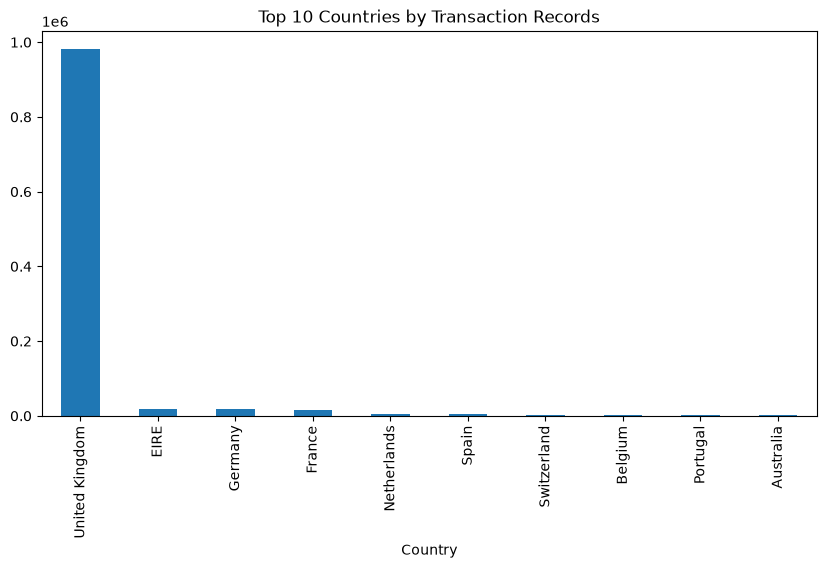

In [12]:
df["Country"].value_counts().head(10).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Top 10 Countries by Transaction Records")
plt.show()

In [13]:
# Convert InvoiceDate to datetime
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

print("Earliest Transaction:", df["InvoiceDate"].min())
print("Latest Transaction:", df["InvoiceDate"].max())

Earliest Transaction: 2009-12-01 07:45:00
Latest Transaction: 2011-12-09 12:50:00


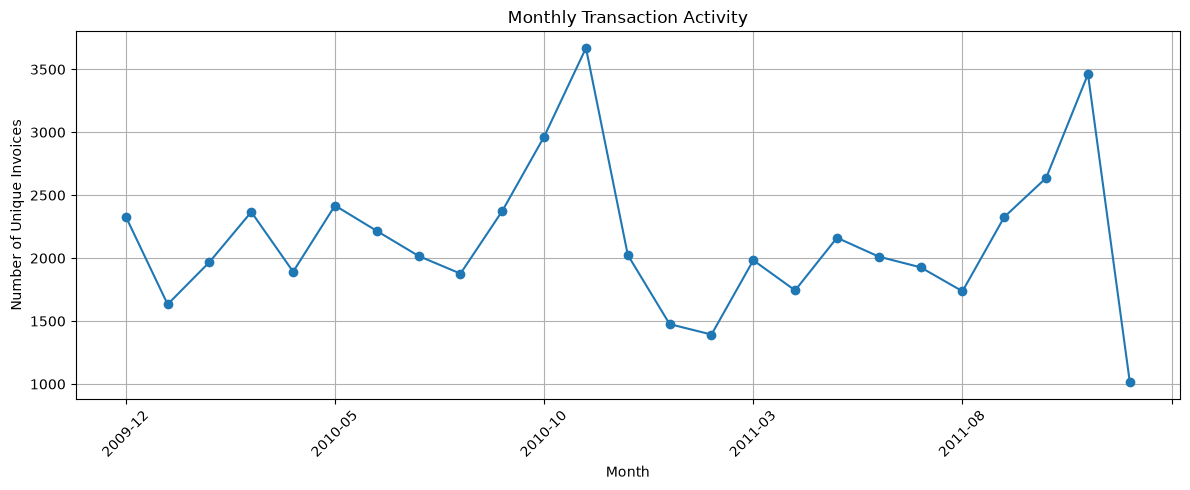

In [18]:
import matplotlib.pyplot as plt

monthly_transactions = (
    df.groupby(df["InvoiceDate"].dt.to_period("M"))["Invoice"]
    .nunique()
)

monthly_transactions.index = monthly_transactions.index.astype(str)

plt.figure(figsize=(12, 5))
monthly_transactions.plot(kind="line", marker="o")

plt.title("Monthly Transaction Activity")
plt.xlabel("Month")
plt.ylabel("Number of Unique Invoices")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# Data cleaning


In [19]:
# Create a separate copy for data cleaning
df_clean = df.copy()

print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:", df_clean.shape)

Original Dataset Shape: (1067371, 8)
Working Dataset Shape: (1067371, 8)


In [20]:
# Count duplicates before removal
duplicates_before = df_clean.duplicated().sum()

# Remove exact duplicates
df_clean = df_clean.drop_duplicates()

print("Duplicates Removed:", duplicates_before)
print("Dataset Shape After Removing Duplicates:", df_clean.shape)
print("Remaining Duplicates:", df_clean.duplicated().sum())

Duplicates Removed: 34335
Dataset Shape After Removing Duplicates: (1033036, 8)
Remaining Duplicates: 0


In [21]:
# Count cancelled invoice records
cancelled_count = df_clean["Invoice"].str.startswith("C").sum()

# Remove cancelled invoices
df_clean = df_clean[
    ~df_clean["Invoice"].str.startswith("C")
].copy()

print("Cancelled Invoice Records Removed:", cancelled_count)
print("Dataset Shape After Removing Cancellations:", df_clean.shape)

# Verify
print("Remaining Cancelled Invoices:",
      df_clean["Invoice"].str.startswith("C").sum())

Cancelled Invoice Records Removed: 19104
Dataset Shape After Removing Cancellations: (1013932, 8)
Remaining Cancelled Invoices: 0


In [22]:
# Store negative quantity records separately
df_returns = df_clean[df_clean["Quantity"] < 0].copy()

print("Return Records:", len(df_returns))

display(df_returns.head())

Return Records: 3393


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom


In [23]:
# Keep only positive quantity transactions
df_clean = df_clean[df_clean["Quantity"] > 0].copy()

print("Negative Quantity Records Removed:", len(df_returns))
print("Dataset Shape After Removing Returns:", df_clean.shape)

print("Remaining Negative Quantities:",
      (df_clean["Quantity"] < 0).sum())

Negative Quantity Records Removed: 3393
Dataset Shape After Removing Returns: (1010539, 8)
Remaining Negative Quantities: 0


In [24]:
# Store negative and zero price records separately
df_price_adjustments = df_clean[
    df_clean["Price"] <= 0
].copy()

print("Negative Price Records:",
      (df_clean["Price"] < 0).sum())

print("Zero Price Records:",
      (df_clean["Price"] == 0).sum())

print("Total Price Adjustment Records:",
      len(df_price_adjustments))

Negative Price Records: 5
Zero Price Records: 2621
Total Price Adjustment Records: 2626


In [25]:
# Retain only transactions with positive prices
df_clean = df_clean[df_clean["Price"] > 0].copy()

print("Dataset Shape After Price Cleaning:", df_clean.shape)

print("Remaining Negative Prices:",
      (df_clean["Price"] < 0).sum())

print("Remaining Zero Prices:",
      (df_clean["Price"] == 0).sum())

Dataset Shape After Price Cleaning: (1007913, 8)
Remaining Negative Prices: 0
Remaining Zero Prices: 0


In [26]:
# Store transactions with missing Customer IDs
df_missing_customers = df_clean[
    df_clean["Customer ID"].isna()
].copy()

print("Records with Missing Customer ID:",
      len(df_missing_customers))

Records with Missing Customer ID: 228488


In [27]:
# Remove transactions without Customer ID
df_clean = df_clean.dropna(
    subset=["Customer ID"]
).copy()

print("Dataset Shape After Removing Missing Customer IDs:",
      df_clean.shape)

print("Remaining Missing Customer IDs:",
      df_clean["Customer ID"].isna().sum())

Dataset Shape After Removing Missing Customer IDs: (779425, 8)
Remaining Missing Customer IDs: 0


In [28]:
# Convert Customer ID to integer
df_clean["Customer ID"] = df_clean["Customer ID"].astype(int)

# Check data types
print(df_clean.dtypes)

Invoice                   str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID             int64
Country                   str
dtype: object


In [29]:
# Calculate revenue for each transaction
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["Price"]

# Display sample records
display(df_clean.head())

# Check revenue statistics
print("Total Revenue:", df_clean["Revenue"].sum())
print("Average Transaction Revenue:", df_clean["Revenue"].mean())

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


Total Revenue: 17374804.268
Average Transaction Revenue: 22.291823161946304


In [30]:
print("Final Dataset Shape:", df_clean.shape) # final data validation

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Records:", df_clean.duplicated().sum())

print("\nNegative Quantities:", (df_clean["Quantity"] < 0).sum())

print("\nNon-positive Prices:", (df_clean["Price"] <= 0).sum())

print("\nNegative Revenue:", (df_clean["Revenue"] < 0).sum())

Final Dataset Shape: (779425, 9)

Missing Values:
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
Revenue        0
dtype: int64

Duplicate Records: 0

Negative Quantities: 0

Non-positive Prices: 0

Negative Revenue: 0


In [31]:
# Save cleaned dataset
df_clean.to_csv(
    "../data/processed/retail_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [32]:
# Load the saved cleaned dataset
df_verify = pd.read_csv(
    "../data/processed/retail_cleaned.csv"
)

print("Verified Dataset Shape:", df_verify.shape)

display(df_verify.head())

Verified Dataset Shape: (779425, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


In [1]:
import os
import pandas as pd

folder = "../data/processed"

for file in os.listdir(folder):
    if file.endswith(".csv"):
        file_path = os.path.join(folder, file)
        data = pd.read_csv(file_path)

        print(f"{file}: {len(data):,} rows and {len(data.columns)} columns")

customer_rfm.csv: 5,878 rows and 9 columns
customer_rfm_ml.csv: 5,878 rows and 10 columns
ml_cluster_profile.csv: 4 rows and 6 columns
retail_cleaned.csv: 779,425 rows and 9 columns
rfm_ml_comparison.csv: 7 rows and 5 columns
segment_summary.csv: 7 rows and 7 columns
